### Second portion of the micrograd for implementing neural nets using pytorch 

In [25]:
import torch
import math
import random

In [26]:
# basically creating tensors and setting the grad property to true since by default they are set to false for optimization reasons
# tensor is basically n dimentional array of scalars
x1 = torch.Tensor([2.0]).double()                ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()                ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()               ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()  ; b.requires_grad = True


n = x1*w1 + x2*w2 + b

o = torch.tanh(n)

# result of forward pass
print(o.data.item())

o.backward()

# these are results of gradients
print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [27]:
class Value:
  
  def __init__(self, data, _children=(), _op='', label=''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda: None
    self._prev = set(_children)
    self._op = _op
    self.label = label

  def __repr__(self):
    return f"Value(data={self.data})"
  
  def __add__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data + other.data, (self, other), '+')
    
    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward
    
    return out

  def __mul__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data * other.data, (self, other), '*')
    
    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward
      
    return out
  
  def __pow__(self, other):
    assert isinstance(other, (int, float)), "only supporting int/float powers for now"
    out = Value(self.data**other, (self,), f'**{other}')

    def _backward():
        self.grad += other * (self.data ** (other - 1)) * out.grad
    out._backward = _backward

    return out
  
  def __rmul__(self, other): # other * self
    return self * other

  def __truediv__(self, other): # self / other
    return self * other**-1

  def __neg__(self): # -self
    return self * -1

  def __sub__(self, other): # self - other
    return self + (-other)

  def __radd__(self, other): # other + self
    return self + other

  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
    out = Value(t, (self, ), 'tanh')
    
    def _backward():
      self.grad += (1 - t**2) * out.grad
    out._backward = _backward
    
    return out
  
  def exp(self):
    x = self.data
    out = Value(math.exp(x), (self, ), 'exp')
    
    def _backward():
      self.grad += out.data * out.grad # NOTE: in the video I incorrectly used = instead of +=. Fixed here.
    out._backward = _backward
    
    return out
  
  
  def backward(self):
    
    topo = []
    visited = set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)
    
    self.grad = 1.0
    for node in reversed(topo):
      node._backward()

In [37]:
from typing import Any


class Neuron:

    # initialize object with weights and bias
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))
    
    # actiavtes when we perform object(x) where x = some values i.e. forward pass
    def __call__(self, x):
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        # this is basically multiply corresponding weights with x i.e. neurons and add bias
        out = act.tanh()
        # then take that sum and apply tanh activation function on it and return the forward pass value
        return out
    
    def parameters(self):
      return self.w + [self.b]

# now using the neurons we can build layers which can be input layer, hidden layers or the output layer
# layer is basically a collection of neurons
class Layer:
  
  def __init__(self, nin, nout):
    self.neurons = [Neuron(nin) for _ in range(nout)]
  
  def __call__(self, x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs

  def parameters(self):
    return [p for neuron in self.neurons for p in neuron.parameters()]


# MLP or multi layer perceptron is a collection of the layers to form a simple neural net.
class MLP:
  
  def __init__(self, nin, nouts):
    sz = [nin] + nouts
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]
  
  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    return x

  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]

In [38]:
# example of using call 
x = [2.0, 3.0]
n = Neuron(2) # initialize object with 2 neurons
n(x)

Value(data=0.6354051450981161)

In [39]:
# example of layer
x = [2.0, 3.0]
n = Layer(2, 3)
# n is a layer with 2 inputs and 3 neurons
n(x)

[Value(data=0.9310047478583278),
 Value(data=0.9604463783228547),
 Value(data=0.9698860203962523)]

In [40]:
# example of MLP
x = [2.0, 3.0, 1.0]
# 3 inputs feed into the neural net with 2 layers each with 4 neurons and produce a single output which is printed
n = MLP(3, [4, 4, 1])
n(x)

Value(data=-0.9609938105190112)

In [41]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

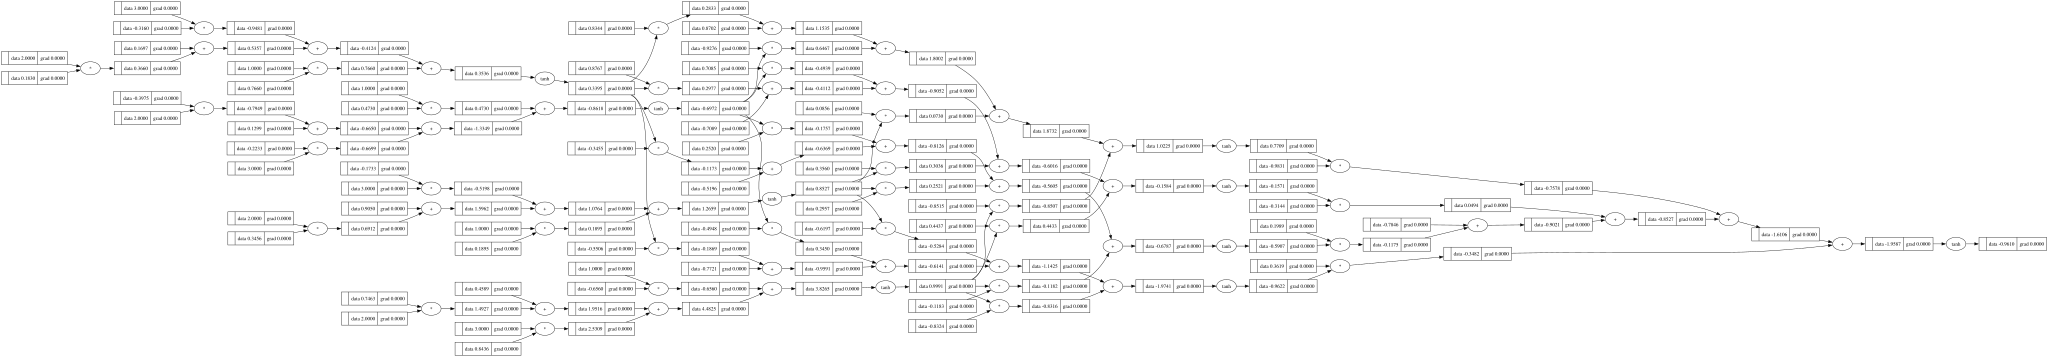

In [42]:
draw_dot(n(x))

In [60]:
# example problem with given inputs xs and we want the output to be ys
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets

# so we want to build a binary classifier neural network 

### so we are training the network by iteratively performing forward pass, backward pass, and then updating based on the loss


In [124]:
# we do 20 iterations/passes
for k in range(20):
  
  # forward pass
  ypred = [n(x) for x in xs]

  # calculating the loss by comparing the output of our neural net with the ground truth and squaring it
  loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
  
  # backward pass
  for p in n.parameters():
    p.grad = 0.0
  
  loss.backward()
  
  # update the params based on the direction of the gradient based on gradient descent
  for p in n.parameters():
    p.data += -0.1 * p.grad # here 0.1 is the learning rate

  # these are basically the total loss per pass
  print(k, loss.data)  

0 0.0001983556437205872
1 0.0001982241802604987
2 0.00019809288819711224
3 0.00019796176719735943
4 0.00019783081692901773
5 0.00019770003706073277
6 0.00019756942726200695
7 0.00019743898720317823
8 0.00019730871655545035
9 0.00019717861499086114
10 0.00019704868218230312
11 0.00019691891780350743
12 0.00019678932152902693
13 0.00019665989303427017
14 0.00019653063199547472
15 0.00019640153808969774
16 0.00019627261099483502
17 0.0001961438503895972
18 0.0001960152559535245
19 0.00019588682736697668


In [ ]:
ypred
# which are almost equal to the pred values in the given problem

[Value(data=0.9931956467590664),
 Value(data=-0.9939235578085687),
 Value(data=-0.9933200916641327),
 Value(data=0.9917511649756965)]